# Penzene documents in Jupyter

For readers who know basic Python and want to draw and edit molecules in a notebook.
By the end you will display phenol inline, make an independent edited copy, save and export it,
and reopen the saved drawing. All chemistry is generated locally; no input download is needed.

Use Python 3.12 or newer. Install into the environment running your notebook:

```sh
python -m pip install penzene jupyterlab
python -m jupyter lab
```

Choose a plain Python kernel. Penzene includes Qt; a kernel that has already loaded PyQt/PySide
or enabled a Qt GUI event loop can conflict with it. Restart with a plain kernel if needed.

1. Create and display a document.
2. Inspect properties and edit a copy.
3. Save, export and reopen.
4. Try a short exercise.

Run the cells from top to bottom. Exports go into `notebook-output/` beside the notebook;
rerunning the export cell replaces these example outputs.

In [1]:
from pathlib import Path
from IPython.display import display
import penzene as pz

print("Penzene", pz.__version__)

Penzene 1.9.0


## 1. Create a document and display it

Phenol is `Oc1ccccc1`. A `Document` renders as SVG when it is the last value in a cell;
there is no need to wrap its SVG in an image helper. Here we choose the RSC drawing style.

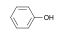

In [2]:
original = pz.from_smiles("Oc1ccccc1")
original.style = "RSC"
assert original.formula == "C6H6O"
original

## 2. Inspect calculated properties

These are the drawn molecule's formula, average molecular weight and neutral monoisotopic mass.
They are calculated values, not measurements.

In [3]:
print("Formula:", original.formula)
print(f"Molecular weight: {original.mw:.2f}")
print(f"Exact mass: {original.exact_mass:.4f}")

Formula: C6H6O
Molecular weight: 94.11
Exact mass: 94.0419


## 3. Edit an independent copy

`edited = original` would give two names for the same mutable document. Copy through `.penz` JSON
instead. Find the oxygen by its symbol and replace OH with the OMe abbreviation, making anisole.
Atoms are read-only views; edits go through the document's methods. The same hotkeys as the desktop app work here: uppercase `O` means OMe. Recalculate indices after
adding or removing atoms rather than relying on an old index list.

Edited: C7H8O COc1ccccc1


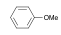

In [4]:
edited = pz.from_json(original.to_json())
oxygen = next(i for i, atom in enumerate(edited.atoms) if atom.symbol == "O")
edited.hotkeys(oxygen, "O")
edited.clean()
assert original.formula == "C6H6O"
assert edited.formula == "C7H8O"
print("Edited:", edited.formula, edited.to_smiles())
edited

## 4. Show more than one document

Only a cell's last value displays automatically. Use `display` explicitly to show both versions
from one cell. The original is still phenol; the edited document is anisole.

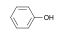

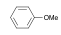

In [5]:
display(original)
display(edited)

## 5. Save and export

`.penz` keeps the editable source. SVG and PDF give vector figures; `to_png(dpi=600)` returns
raster bytes at 600 dpi. File names are explicit, and these outputs are kept in their own folder.

In [6]:
output = Path("notebook-output")
output.mkdir(exist_ok=True)
edited.save(str(output / "anisole.penz"))
edited.export(str(output / "anisole.svg"))
edited.export(str(output / "anisole.pdf"))
(output / "anisole-600dpi.png").write_bytes(edited.to_png(dpi=600))
for path in sorted(output.glob("anisole*")):
    print(path.as_posix())

notebook-output/anisole-600dpi.png
notebook-output/anisole.pdf
notebook-output/anisole.penz
notebook-output/anisole.svg


## 6. Reopen the drawing

Read the saved source and check that its chemistry survived. The saved SVG also carries the
editable drawing. In the desktop app you can open `anisole.penz`, edit it and save; call `pz.read`
again afterwards to load those changes. An existing Python object does not update by itself.

Reopened: C7H8O


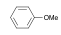

In [7]:
reopened = pz.read(str(output / "anisole.penz"))
assert reopened.to_smiles() == edited.to_smiles()
assert pz.read(str(output / "anisole.svg")).to_smiles() == edited.to_smiles()
print("Reopened:", reopened.formula)
reopened

## Exercise

Make a second independent copy of the original phenol and replace OH with F. Predict its formula
before running the answer cell. Check that the original phenol is unchanged.

In [8]:
# Answer: replacing OH with F gives fluorobenzene, C6H5F.
fluoro = pz.from_json(original.to_json())
oxygen = next(i for i, atom in enumerate(fluoro.atoms) if atom.symbol == "O")
fluoro.hotkeys(oxygen, "f")
assert fluoro.formula == "C6H5F"
assert original.formula == "C6H6O"
print(fluoro.formula, fluoro.to_smiles())

C6H5F Fc1ccccc1


## Continue

Try your own SMILES or use `pz.read("drawing.mol")`, `pz.read("drawing.penz")` or
`pz.read("drawing.cdxml")` as the input. A saved drawing keeps its layout until you call `clean()`.
See the Python API reference for the editing methods available in your installed version:
https://penzene.readthedocs.io/en/latest/python-api.html